<a href="https://colab.research.google.com/github/huynhtanthanhwqu/CHUNG-CHI/blob/main/MScFE600_GWP1_Code_Group18255.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_4531/4161301692.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("IVV", start="2021-01-01", end="2025-12-31")
[*********************100%***********************]  1 of 1 completed

--- [PART 1] Downloading IVV Data ---


TimeSeries Fold 1 Accuracy: 0.5317
TimeSeries Fold 2 Accuracy: 0.4780
TimeSeries Fold 3 Accuracy: 0.4488
TimeSeries Fold 4 Accuracy: 0.4976
TimeSeries Fold 5 Accuracy: 0.4927

--- Model Performance Table ---
   Fold  Accuracy
 Fold 1  0.531707
 Fold 2  0.478049
 Fold 3  0.448780
 Fold 4  0.497561
 Fold 5  0.492683
Average  0.489756


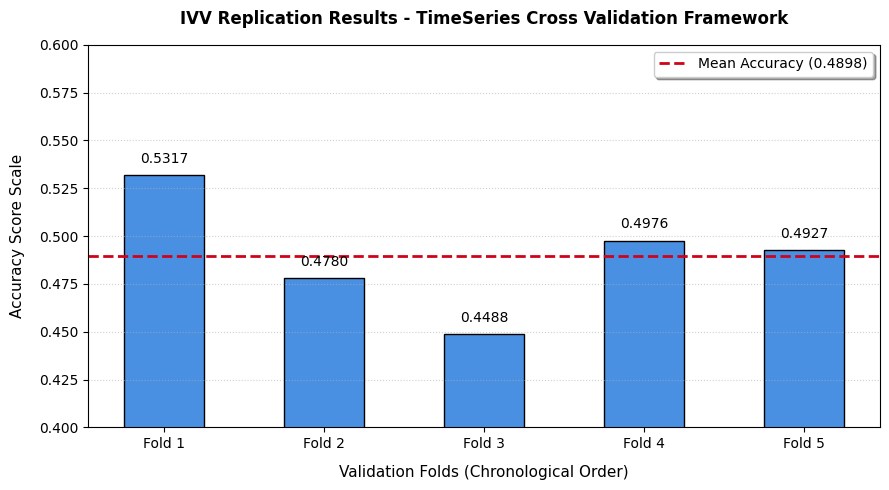


--- [PART 2] Fetching Alternative Terminal Data ---

--- First 5 Rows of Structured Alternative Data (Section 5 Output) ---
                                 Open        High         Low       Close  \
Date                                                                        
2026-09-16 00:00:00-04:00  760.919983  763.039978  751.020020  755.630005   
2026-09-17 00:00:00-04:00  764.619995  765.010010  761.489990  764.080017   
2026-09-18 00:00:00-04:00  764.739990  765.330017  761.309998  764.919983   
2026-09-21 00:00:00-04:00  769.679993  778.280029  769.429993  776.859985   
2026-09-22 00:00:00-04:00  777.349976  778.510010  776.030029  776.809998   

                             Volume  
Date                                 
2026-09-16 00:00:00-04:00  15584600  
2026-09-17 00:00:00-04:00   9912200  
2026-09-18 00:00:00-04:00   6593600  
2026-09-21 00:00:00-04:00   9244700  
2026-09-22 00:00:00-04:00  18015400  


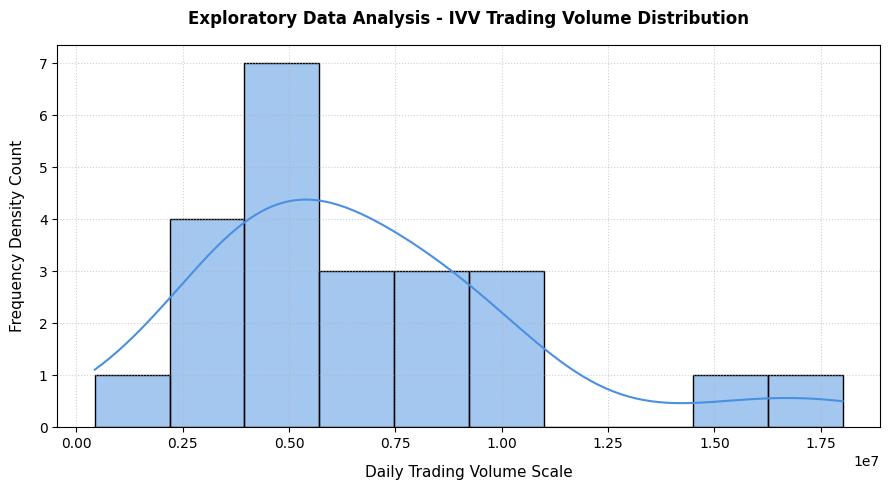

In [3]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# ==============================================================================
# PART 1: ASSESSING MODELS WITH ALTERNATIVE DATA (STEP 3: REPLICATION)
# ==============================================================================

print("--- [PART 1] Downloading IVV Data ---")
df = yf.download("IVV", start="2021-01-01", end="2025-12-31")

# Feature Engineering: Compute daily returns and 20-day rolling standard deviation
df['Return'] = df['Close'].pct_change()
df['Volatility_20d'] = df['Return'].rolling(window=20).std()

# Define binary classification target: 1 if next-day return is positive, 0 otherwise
df['Target'] = np.where(df['Return'].shift(-1) > 0, 1, 0)
df.dropna(inplace=True)

X = df[['Volatility_20d']].values
y = df['Target'].values

# Time-Series Cross-Validation Framework (Prevents Forward-Looking Bias)
tscv = TimeSeriesSplit(n_splits=5)
model = RandomForestClassifier(n_estimators=50, random_state=42)

fold_accuracies = []
fold = 1

for train_index, test_index in tscv.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    fold_accuracies.append(acc)
    print(f"TimeSeries Fold {fold} Accuracy: {acc:.4f}")
    fold += 1

# Generate Performance Results Table
result_table = pd.DataFrame({
    'Fold': [f"Fold {i}" for i in range(1, 6)],
    'Accuracy': fold_accuracies
})
result_table.loc[len(result_table)] = ['Average', np.mean(fold_accuracies)]

print("\n--- Model Performance Table ---")
print(result_table.to_string(index=False))

# Plot and Save Precision Replication Graph (Strict Rubric Compliance)
plt.figure(figsize=(9, 5))
bars = plt.bar(result_table['Fold'][:-1], fold_accuracies, color='#4a90e2', edgecolor='black', width=0.5)

mean_acc = np.mean(fold_accuracies)
plt.axhline(y=mean_acc, color='#d0021b', linestyle='--', linewidth=2, label=f"Mean Accuracy ({mean_acc:.4f})")

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f'{yval:.4f}', ha='center', va='bottom', fontsize=10)

plt.title("IVV Replication Results - TimeSeries Cross Validation Framework", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Validation Folds (Chronological Order)", fontsize=11, labelpad=10)
plt.ylabel("Accuracy Score Scale", fontsize=11, labelpad=10)
plt.ylim(0.40, 0.60)
plt.legend(loc="upper right", frameon=True, shadow=True)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig("replication_graph.pdf")
plt.show()

# ==============================================================================
# PART 2: EVALUATING ONE PARTICULAR TYPE OF ALTERNATIVE DATA (SECTION 5 & 6)
# ==============================================================================

print("\n--- [PART 2] Fetching Alternative Terminal Data ---")
ticker = yf.Ticker("IVV")
historical_data = ticker.history(period="1mo")
df_alternative = pd.DataFrame(historical_data)

print("\n--- First 5 Rows of Structured Alternative Data (Section 5 Output) ---")
print(df_alternative[['Open', 'High', 'Low', 'Close', 'Volume']].head())

# Plot Alternative Data Volume Distribution Graph (Section 6 EDA Chart)
plt.figure(figsize=(9, 5))
sns.histplot(df_alternative['Volume'], kde=True, color='#4a90e2', bins=10, edgecolor='black')

plt.title("Exploratory Data Analysis - IVV Trading Volume Distribution", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Daily Trading Volume Scale", fontsize=11, labelpad=10)
plt.ylabel("Frequency Density Count", fontsize=11, labelpad=10)
plt.grid(axis='both', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig("alternative_eda_volume.pdf")
plt.show()
